In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Formation plot

[[ 0.02576052  0.54828738 -0.13920942 -1.00318009 -1.06295826  1.10838442
   1.11857774  0.57111998]
 [-0.59096927  0.0222632   0.34629195 -0.51565993  0.20769649 -0.56014792
   0.28568192  0.66814097]
 [-1.39302643  0.58631807 -2.84446966 -0.57210556  2.03477767  0.44730757
  -2.79137411  0.06005052]]


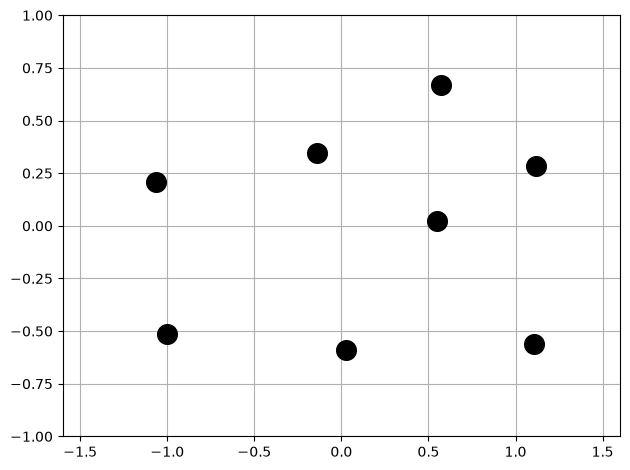

In [5]:
N = 9
x = np.array([[-0.7, -0.45, 0., 0.45, 0.7, -0.35, 0.35, 0., 0.],
              [-0.15, -0.38, -0.5, -0.38, -0.15, 0.28, 0.28, 0., -0.25]])
x = np.array([[0.02576052,  0.54828738, -0.13920942, -1.00318009, -1.06295826,  1.10838442, 1.11857774,  0.57111998],
 [-0.59096927,  0.0222632,   0.34629195, -0.51565993,  0.20769649, -0.56014792, 0.28568192,  0.66814097],
 [-1.39302643,  0.58631807, -2.84446966, -0.57210556,  2.03477767,  0.44730757, -2.79137411,  0.06005052]])
print(x)
fig, ax = plt.subplots(1,1,layout='tight')
ax.grid()
ax.set_axisbelow(True)
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(len(x[0,:])):
    ax.scatter(x[0,i],x[1,i],s=200,color='black')
plt.show()

# Comm. graph

Adjacency matrix:
[[0 1 1 0 0 1 0 0 1]
 [1 0 1 1 0 1 0 0 0]
 [1 1 0 1 1 0 0 1 1]
 [0 1 1 0 1 0 1 0 0]
 [0 0 1 1 0 0 1 0 1]
 [1 1 0 0 0 0 1 1 0]
 [0 0 0 1 1 1 0 1 0]
 [0 0 1 0 0 1 1 0 1]
 [1 0 1 0 1 0 0 1 0]]
[[0.         0.33970576 0.78262379 0.         0.         0.55443665
  0.         0.         0.70710678]
 [0.33970576 0.         0.46572524 0.9        0.         0.66753277
  0.         0.         0.        ]
 [0.78262379 0.46572524 0.         0.46572524 0.78262379 0.
  0.         0.5        0.25      ]
 [0.         0.9        0.46572524 0.         0.33970576 0.
  0.66753277 0.         0.        ]
 [0.         0.         0.78262379 0.33970576 0.         0.
  0.55443665 0.         0.70710678]
 [0.55443665 0.66753277 0.         0.         0.         0.
  0.7        0.4482187  0.        ]
 [0.         0.         0.         0.66753277 0.55443665 0.7
  0.         0.4482187  0.        ]
 [0.         0.         0.5        0.         0.         0.4482187
  0.4482187  0.         0.25      ]


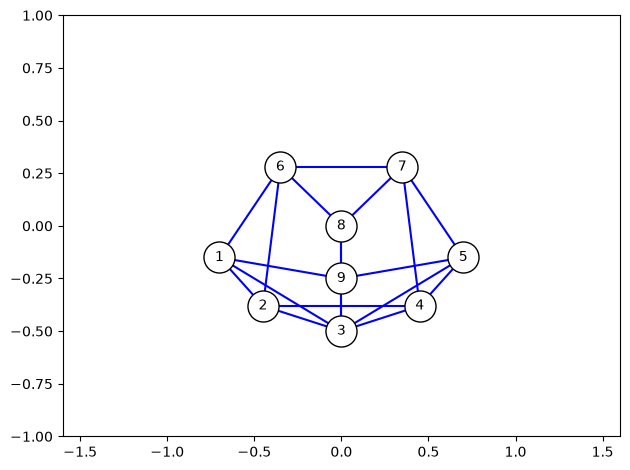

In [21]:
# adjacency_mat = np.zeros((x.shape[1],x.shape[1]))
# for i in range(-1,len(adjacency_mat)-1):
#     adjacency_mat[i,i+1] = 1
# #     adjacency_mat[1,i+1] = 1
# # adjacency_mat[1,1] = 0; adjacency_mat[1,0] = 0
# #adjacency_mat [1,1] = 0
# adjacency_mat[0,6] = 1
# adjacency_mat[1,5] = 1; adjacency_mat[1,6] = 1
# adjacency_mat[2,4] = 1; adjacency_mat[2,5] = 1
# adjacency_mat[3,7] = 1
# adjacency_mat = adjacency_mat + adjacency_mat.transpose()
# # print(adjacency_mat)


# Initialize adjacency matrix
adjacency_mat = np.zeros((N, N), dtype=int)
distance_mat = np.zeros((N,N))

# Define undirected communication edges
edges = [
    # Smile (robots 1-5)
    (1, 2),
    (2, 3),
    (3, 4),
    (4, 5),
    (1, 3),
    (2, 4),
    (3, 5),

    # Eyes (robots 6-7)
    (1, 6),
    (2, 6),
    (4, 7),
    (5, 7),
    (6, 7),

    # Nose (robot 8)
    (3, 8),
    (6, 8),
    (7, 8),

    (1,9),(3,9),(5,9),(8,9)
]

# Populate adjacency matrix
for i, j in edges:
    adjacency_mat[i-1, j-1] = 1
    adjacency_mat[j-1, i-1] = 1

print("Adjacency matrix:")
print(adjacency_mat)

fig, ax = plt.subplots(1,1,layout='tight')
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(adjacency_mat.shape[0]):
    for j in range(i,adjacency_mat.shape[1]):
        if adjacency_mat[i,j] == 1:
            distance_mat[i,j] = np.linalg.norm(x[:,i]-x[:,j])
            ax.plot([x[0,i],x[0,j]],[x[1,i],x[1,j]],zorder=1,color='blue')
distance_mat = distance_mat + distance_mat.transpose()
for i in range(x.shape[1]):
    ax.scatter(x[0,i],x[1,i],s=500,facecolors='white',edgecolors='black',zorder=2)
    ax.text(x[0,i],x[1,i],s=str(i+1),ha='center',va='center')
print(distance_mat)
plt.show()


## Laplacian

In [18]:
L = np.diag(np.sum(adjacency_mat, axis=1)) - adjacency_mat
print(L)

[[ 3 -1 -1  0  0 -1  0  0]
 [-1  4 -1 -1  0 -1  0  0]
 [-1 -1  5 -1 -1  0  0 -1]
 [ 0 -1 -1  4 -1  0 -1  0]
 [ 0  0 -1 -1  3  0 -1  0]
 [-1 -1  0  0  0  4 -1 -1]
 [ 0  0  0 -1 -1 -1  4 -1]
 [ 0  0 -1  0  0 -1 -1  3]]


# Simulation...

In [21]:
distance_sim = np.load('../data/smile_distance_formation.npy')
print(distance_sim.shape)

(3, 8, 2000)


(3, 8, 2000)


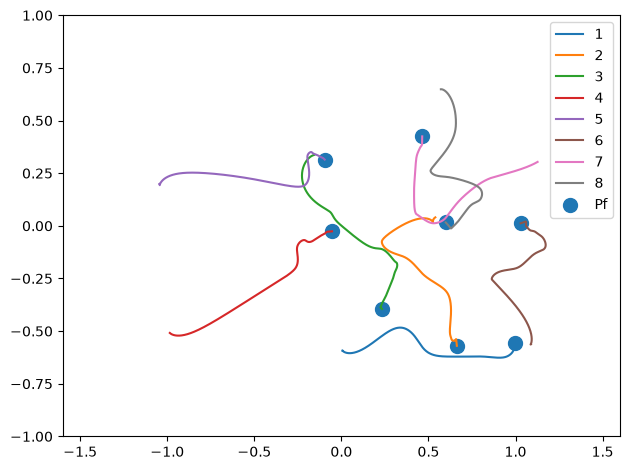

In [24]:
fig, ax = plt.subplots(1,1, layout='tight')
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
print(distance_sim.shape)
for i in range(distance_sim.shape[1]):
    ax.plot(distance_sim[0,i,:],distance_sim[1,i,:], label=f'{i+1}')
ax.scatter(distance_sim[0,:,-1],distance_sim[1,:,-1], s=100, label = 'Pf')
ax.legend()

# Leader-folower exercise

## Displacement-based no leader

### Simulation

In [2]:
positions_1b = np.load('../data/leader_follower_displacement_smile.npy')
center_1b = np.load('../data/leader_follower_displacement_smile_centers.npy')

(5, 3000)


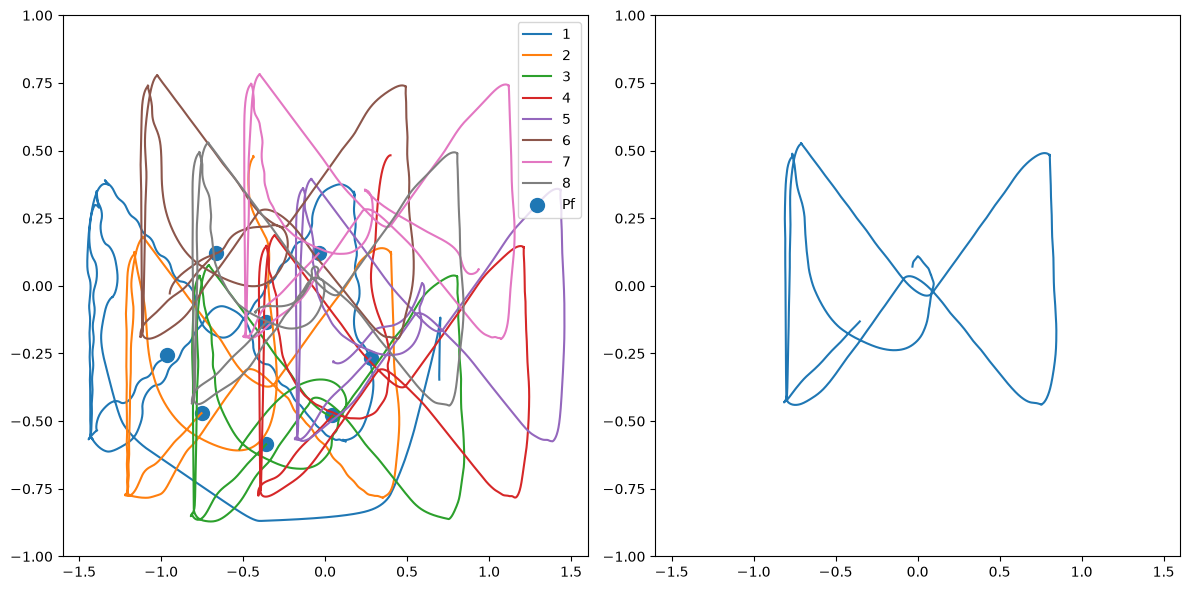

In [7]:
fig, (ax, ax2)= plt.subplots(1,2, figsize=(12,6),layout='tight')
ax.set_xlim(-1.6,1.6)
ax.set_ylim(-1,1)
for i in range(positions_1b.shape[1]):
    ax.plot(positions_1b[0,i,:],positions_1b[1,i,:], label=f'{i+1}')
ax.scatter(positions_1b[0,:,-1],positions_1b[1,:,-1], s=100, label = 'Pf')
ax.legend()

print(center_1b.shape)
ax2.set_xlim(-1.6,1.6)
ax2.set_ylim(-1,1)
ax2.plot(center_1b[3,:],center_1b[4,:])

## Leader-follower waypoints

In [20]:
# =========================================================
# GRAPH TOPOLOGY
# =========================================================
# Adjacency Matrix
adjacency_mat_2 = np.zeros((9,9), dtype=int)

# Define undirected communication edges
edges_2 = [
    # Smile (robots 1-5)
    (1, 2),(2, 3),(3, 4),(4, 5),(1, 3),(2, 4),(3, 5),
    # Eyes (robots 6-7)
    (1, 6),(2, 6),(4, 7),(5, 7),(6, 7),
    # Nose (robot 8)
    (3, 8),(6, 8),(7, 8)]

for i, j in edges_2:
    adjacency_mat_2[i, j] = 1
    adjacency_mat_2[j, i] = 1

# Laplacian for a 2D-rigid smile formation
L_2 = np.diag(np.sum(adjacency_mat_2, axis=1)) - adjacency_mat_2
print(L)
print(L_2)

[[ 3 -1 -1  0  0 -1  0  0]
 [-1  4 -1 -1  0 -1  0  0]
 [-1 -1  5 -1 -1  0  0 -1]
 [ 0 -1 -1  4 -1  0 -1  0]
 [ 0  0 -1 -1  3  0 -1  0]
 [-1 -1  0  0  0  4 -1 -1]
 [ 0  0  0 -1 -1 -1  4 -1]
 [ 0  0 -1  0  0 -1 -1  3]]
[[ 0  0  0  0  0  0  0  0  0]
 [ 0  3 -1 -1  0  0 -1  0  0]
 [ 0 -1  4 -1 -1  0 -1  0  0]
 [ 0 -1 -1  5 -1 -1  0  0 -1]
 [ 0  0 -1 -1  4 -1  0 -1  0]
 [ 0  0  0 -1 -1  3  0 -1  0]
 [ 0 -1 -1  0  0  0  4 -1 -1]
 [ 0  0  0  0 -1 -1 -1  4 -1]
 [ 0  0  0 -1  0  0 -1 -1  3]]


# Proximity-based communication

In [7]:
N = 8
radius = 1
def adj_matrix(x,R=radius):
    adjacency_mat = np.zeros((N,N), dtype=int)
    for i in range(N):
        for j in range(i+1,N):
            if np.linalg.norm(x[:,i]-x[:,j]) < R:
                adjacency_mat[i,j] = 1
                adjacency_mat[j,i] = 1
    return adjacency_mat

initial_conditions = np.array([[0.02576052,  0.54828738, -0.13920942, -1.00318009, -1.06295826,  1.10838442, 1.11857774,  0.57111998],
 [-0.59096927,  0.0222632,   0.34629195, -0.51565993,  0.20769649, -0.56014792, 0.28568192,  0.66814097],
 [-1.39302643,  0.58631807, -2.84446966, -0.57210556,  2.03477767,  0.44730757, -2.79137411,  0.06005052]])

adjacency_mat = adj_matrix(initial_conditions[:2,:])
print(adjacency_mat)

[[0 1 1 0 0 0 0 0]
 [1 0 1 0 0 1 1 1]
 [1 1 0 0 1 0 0 1]
 [0 0 0 0 1 0 0 0]
 [0 0 1 1 0 0 0 0]
 [0 1 0 0 0 0 1 0]
 [0 1 0 0 0 1 0 1]
 [0 1 1 0 0 0 1 0]]
